
AfroSymbolic/
│
├── data/
│   ├── raw/
│   │   ├── videos/
│   │   └── audio/
│   │
│   ├── processed/
│   │   ├── segments/
│   │   ├── spectrograms/
│   │   └── features/
│   │
│   ├── annotations/
│   │   └── events/
│   │
│   ├── symbolic/
│   │   ├── cycles/
│   │   └── patterns/
│   │
│   └── metadata/
│       ├── videos_alekpehanhou.csv
│       ├── recordings.csv
│       ├── events.csv
│       ├── cycles.csv
│       └── generations.csv
│
├── notebooks/
│   ├── 01_data_exploration.ipynb
│   ├── 02_audio_processing.ipynb
│   ├── 03_percussion_detection.ipynb
│   ├── 04_rhythm_analysis.ipynb
│   ├── 05_cycle_detection.ipynb
│   ├── 06_symbolic_representation.ipynb
│   └── 07_rhythm_generation.ipynb
│
├── src/
│   └── afrosymbolic/
│       ├── collection/
│       ├── audio/
│       ├── detection/
│       ├── annotation/
│       ├── rhythm/
│       ├── cycle_detection/
│       ├── representation/
│       ├── generator/
│       ├── evaluation/
│       └── visualization/
│
├── outputs/
│   ├── midi/
│   ├── figures/
│   └── reports/
│
├── tests/
├── requirements.txt
└── README.md


In [5]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

In [12]:
DATA_PATH = Path("../data/metadata/videos_alekpehanhou.csv")

df = pd.read_csv(DATA_PATH, sep=";")
print(f"Nombre de vidéos : {len(df)}")
df.head()

Nombre de vidéos : 45


,titre,lien,temps,chemin_video,chemin_audio,statut
0,Kpo Dè Médé Nu Na Fiô,https://www.youtube.com/watch?v=LKiEfiBv_Nw,00:09:00,../data/raw/video/LKiEfiBv_Nw.mp4,../data/raw/audio/LKiEfiBv_Nw.wav,ok
1,Médé Kun No Nywè Nui Hu Se O,https://www.youtube.com/watch?v=s3VsrDsImKc,00:06:19,../data/raw/video/s3VsrDsImKc.mp4,../data/raw/audio/s3VsrDsImKc.wav,ok
2,Axwawlé,https://www.youtube.com/watch?v=HasdEkSxT-M,00:09:12,../data/raw/video/HasdEkSxT-M.mp4,../data/raw/audio/HasdEkSxT-M.wav,ok
3,Dodonusi No Gb'a Su A ?,https://www.youtube.com/watch?v=95IBcJ6cSXI,00:10:03,../data/raw/video/95IBcJ6cSXI.mp4,../data/raw/audio/95IBcJ6cSXI.wav,ok
4,Jonion d'Alakénu,https://www.youtube.com/watch?v=epEyMwnIAcw,00:08:52,../data/raw/video/epEyMwnIAcw.mp4,../data/raw/audio/epEyMwnIAcw.wav,ok


In [13]:
EXPECTED_COLUMNS = [
    "titre",
    "lien",
    "temps",
    "chemin_video",
    "chemin_audio",
    "statut"
]

missing_columns = set(EXPECTED_COLUMNS) - set(df.columns)

if missing_columns:
    raise ValueError(f"Colonnes manquantes : {missing_columns}")

print("Dimensions :", df.shape)
print("\nTypes des colonnes :")
print(df.dtypes)

print("\nInformations générales :")
df.info()

Dimensions : (45, 6)

Types des colonnes :
titre           str
lien            str
temps           str
chemin_video    str
chemin_audio    str
statut          str
dtype: object

Informations générales :
<class 'pandas.DataFrame'>
RangeIndex: 45 entries, 0 to 44
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   titre         45 non-null     str  
 1   lien          45 non-null     str  
 2   temps         45 non-null     str  
 3   chemin_video  44 non-null     str  
 4   chemin_audio  44 non-null     str  
 5   statut        45 non-null     str  
dtypes: str(6)
memory usage: 2.2 KB


In [14]:
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": df.isna().mean() * 100
})

missing.sort_values(
    "missing_percentage",
    ascending=False
)

,missing_count,missing_percentage
chemin_video,1,2.222222
chemin_audio,1,2.222222
titre,0,0.000000
lien,0,0.000000
temps,0,0.000000
statut,0,0.000000


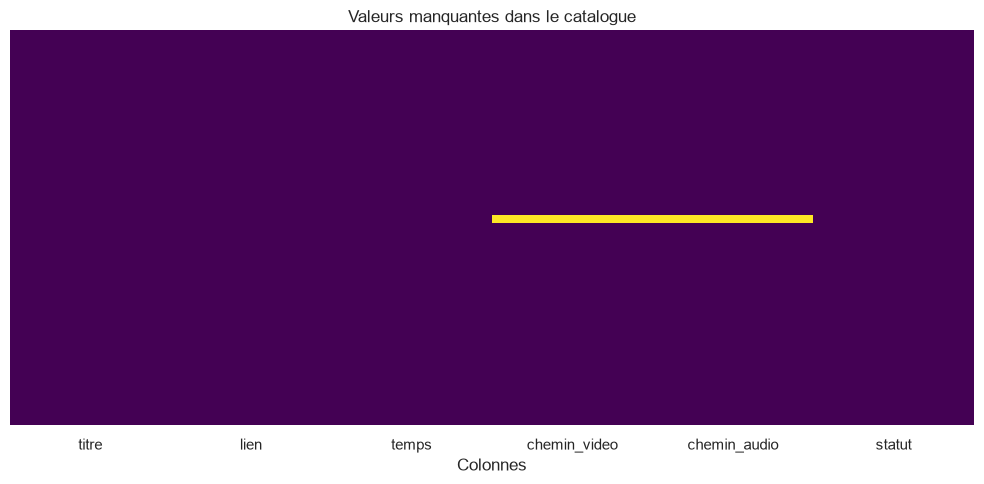

In [16]:
plt.figure(figsize=(10, 5))

sns.heatmap(
    df.isna(),
    cbar=False,
    yticklabels=False,
    cmap="viridis"
)

plt.title("Valeurs manquantes dans le catalogue")
plt.xlabel("Colonnes")
plt.tight_layout()
plt.show()

In [24]:
df.dropna(subset=["chemin_video", "chemin_audio"], inplace=True)

/var/folders/06/0y965bks7nz6mll8dv_nl1lw0000gn/T/ipykernel_69515/3283704770.py:1: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(subset=["chemin_video", "chemin_audio"], inplace=True)


In [25]:
def duration_to_seconds(value):
    if pd.isna(value):
        return np.nan

    parts = str(value).split(":")

    try:
        parts = [int(part) for part in parts]

        if len(parts) == 3:
            hours, minutes, seconds = parts
            return hours * 3600 + minutes * 60 + seconds

        if len(parts) == 2:
            minutes, seconds = parts
            return minutes * 60 + seconds

        if len(parts) == 1:
            return parts[0]

    except ValueError:
        return np.nan

    return np.nan


df["duree_secondes"] = df["temps"].apply(duration_to_seconds)

df[["titre", "temps", "duree_secondes"]].head()

,titre,temps,duree_secondes
0,Kpo Dè Médé Nu Na Fiô,00:09:00,540
1,Médé Kun No Nywè Nui Hu Se O,00:06:19,379
2,Axwawlé,00:09:12,552
3,Dodonusi No Gb'a Su A ?,00:10:03,603
4,Jonion d'Alakénu,00:08:52,532


In [26]:
df["duree_secondes"].describe()

count      44.000000
mean      527.363636
std       234.079900
min       305.000000
25%       425.500000
50%       479.000000
75%       548.250000
max      1668.000000
Name: duree_secondes, dtype: float64

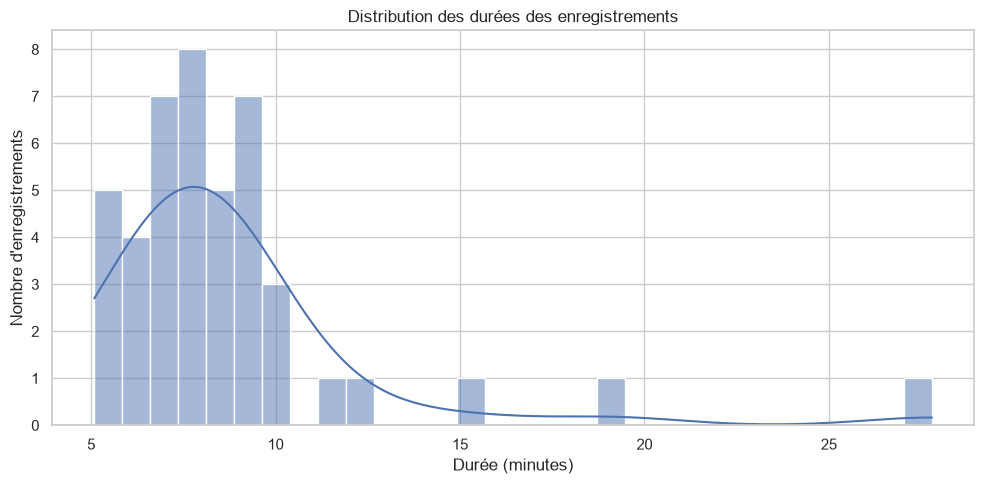

In [27]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["duree_secondes"].dropna() / 60,
    bins=30,
    kde=True
)

plt.xlabel("Durée (minutes)")
plt.ylabel("Nombre d'enregistrements")
plt.title("Distribution des durées des enregistrements")

plt.tight_layout()
plt.show()

statut
ok    44
Name: count, dtype: int64


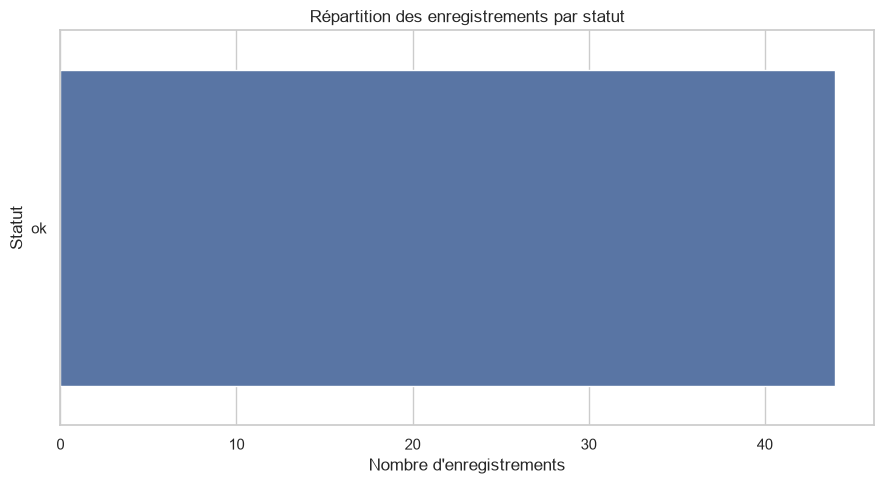

In [28]:
status_counts = df["statut"].value_counts(dropna=False)

print(status_counts)

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    y="statut",
    order=df["statut"].value_counts().index
)

plt.title("Répartition des enregistrements par statut")
plt.xlabel("Nombre d'enregistrements")
plt.ylabel("Statut")

plt.tight_layout()
plt.show()

In [29]:
def file_exists(path):
    if pd.isna(path) or not str(path).strip():
        return False

    return Path(path).is_file()


df["video_exists"] = df["chemin_video"].apply(file_exists)
df["audio_exists"] = df["chemin_audio"].apply(file_exists)

print("Vidéos disponibles :", df["video_exists"].sum())
print("Audios disponibles :", df["audio_exists"].sum())

print("\nFichiers audio absents :")
display(
    df.loc[
        ~df["audio_exists"],
        ["titre", "chemin_audio", "statut"]
    ].head(10)
)

Vidéos disponibles : 44
Audios disponibles : 44

Fichiers audio absents :


,titre,chemin_audio,statut


In [30]:
print("Doublons de liens :", df["lien"].duplicated().sum())
print("Doublons de titres :", df["titre"].duplicated().sum())

duplicates = df[df.duplicated(subset=["lien"], keep=False)]

display(duplicates.sort_values("lien"))

Doublons de liens : 0
Doublons de titres : 0


,titre,lien,temps,chemin_video,chemin_audio,statut,duree_secondes,video_exists,audio_exists


In [31]:
report = {
    "total_recordings": len(df),
    "unique_titles": df["titre"].nunique(),
    "unique_links": df["lien"].nunique(),
    "available_audio": int(df["audio_exists"].sum()),
    "available_videos": int(df["video_exists"].sum()),
    "missing_audio": int((~df["audio_exists"]).sum()),
    "missing_durations": int(df["duree_secondes"].isna().sum()),
    "duplicate_links": int(df["lien"].duplicated().sum()),
    "total_audio_duration_hours": round(
        df.loc[df["audio_exists"], "duree_secondes"].sum() / 3600,
        2
    )
}

pd.Series(report, name="value")

total_recordings              44.00
unique_titles                 44.00
unique_links                  44.00
available_audio               44.00
available_videos              44.00
missing_audio                  0.00
missing_durations              0.00
duplicate_links                0.00
total_audio_duration_hours     6.45
Name: value, dtype: float64

![Repport](../img/report.png)

In [32]:
OUTPUT_PATH = Path("../data/metadata/recordings_exploration.csv")

OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)

df.to_csv(
    OUTPUT_PATH,
    index=False,
    encoding="utf-8"
)

print(f"Catalogue sauvegardé : {OUTPUT_PATH}")

Catalogue sauvegardé : ../data/metadata/recordings_exploration.csv


In [33]:
import soundfile as sf

audio_info = []

for _, row in df.iterrows():
    path = Path(row["chemin_audio"])

    info = sf.info(path)

    audio_info.append({
        "titre": row["titre"],
        "format": info.format,
        "subtype": info.subtype,
        "sample_rate": info.samplerate,
        "channels": info.channels,
        "duration_seconds": info.duration,
    })

audio_df = pd.DataFrame(audio_info)

display(audio_df.head())

,titre,format,subtype,sample_rate,channels,duration_seconds
0,Kpo Dè Médé Nu Na Fiô,WAV,PCM_16,44100,2,539.771066
1,Médé Kun No Nywè Nui Hu Se O,WAV,PCM_16,44100,2,378.578141
2,Axwawlé,WAV,PCM_16,44100,2,551.915102
3,Dodonusi No Gb'a Su A ?,WAV,PCM_16,44100,2,597.542313
4,Jonion d'Alakénu,WAV,PCM_16,44100,2,531.806621


In [34]:
print("Fréquences d'échantillonnage :")
print(audio_df["sample_rate"].value_counts())

print("\nNombre de canaux :")
print(audio_df["channels"].value_counts())

print("\nStatistiques des durées :")
display(audio_df["duration_seconds"].describe())

Fréquences d'échantillonnage :
sample_rate
44100    44
Name: count, dtype: int64

Nombre de canaux :
channels
2    44
Name: count, dtype: int64

Statistiques des durées :


count      44.000000
mean      526.548357
std       232.959252
min       304.738685
25%       425.273469
50%       477.402268
75%       547.944490
max      1658.044082
Name: duration_seconds, dtype: float64

In [37]:
# Sélectionner l'enregistrement proche de la durée médiane
median_duration = audio_df["duration_seconds"].median()

idx = (audio_df["duration_seconds"] - median_duration).abs().idxmin()

selected = audio_df.loc[idx]
audio_path = Path(df.loc[idx, "chemin_audio"])

# Charger le signal
signal, sample_rate = sf.read(audio_path)

print("Titre :", selected["titre"])
print("Forme du signal :", signal.shape)
print("Fréquence :", sample_rate)
print("Durée :", round(len(signal) / sample_rate, 2), "secondes")

Titre : Oun Do Kou Nou Tevi
Forme du signal : (19443712, 2)
Fréquence : 44100
Durée : 440.9 secondes


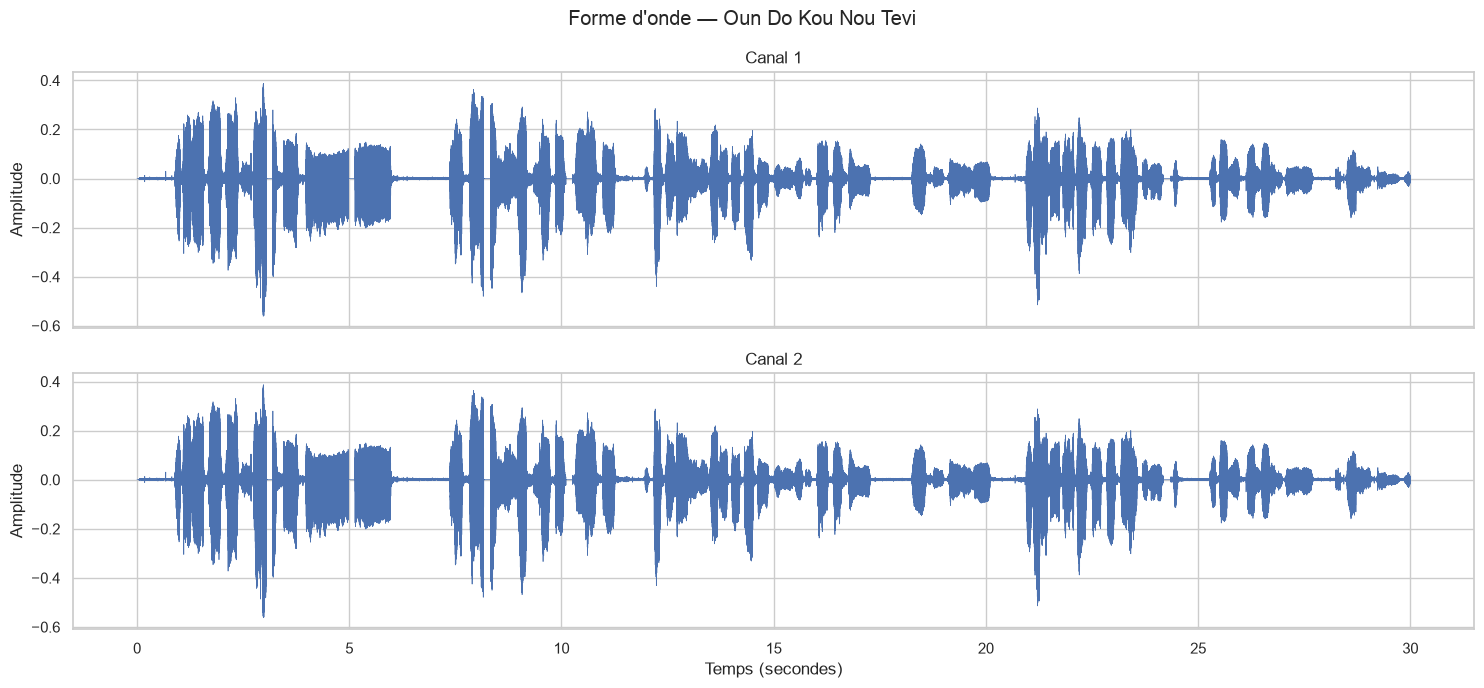

In [38]:
duration_to_plot = 30

n_samples = int(duration_to_plot * sample_rate)

time = np.arange(n_samples) / sample_rate

fig, axes = plt.subplots(2, 1, figsize=(15, 7), sharex=True)

for channel in range(2):
    axes[channel].plot(
        time,
        signal[:n_samples, channel],
        linewidth=0.5
    )

    axes[channel].set_title(f"Canal {channel + 1}")
    axes[channel].set_ylabel("Amplitude")
    axes[channel].grid(True)

axes[-1].set_xlabel("Temps (secondes)")

plt.suptitle(f"Forme d'onde — {selected['titre']}")
plt.tight_layout()
plt.show()

In [41]:
from scipy.signal import spectrogram

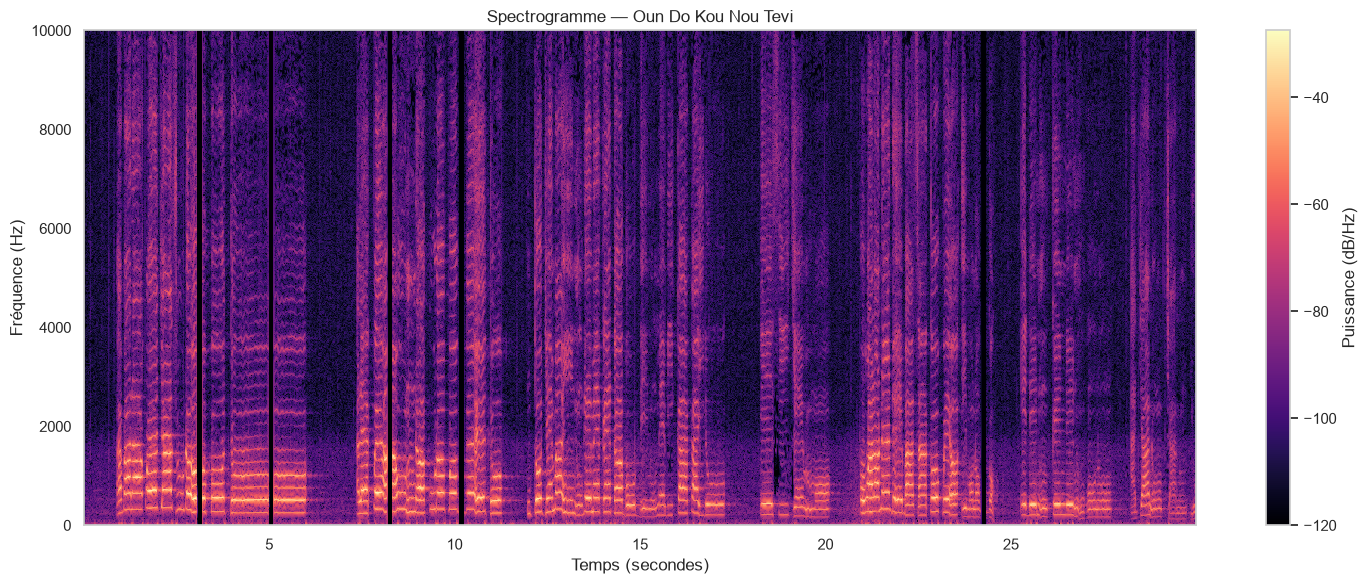

In [42]:
# Moyenne des deux canaux pour une première exploration
mono_signal = signal.mean(axis=1)

frequencies, times, Sxx = spectrogram(
    mono_signal,
    fs=sample_rate,
    nperseg=2048,
    noverlap=1536
)

# Limiter l'affichage aux 30 premières secondes
mask = times <= 30

plt.figure(figsize=(15, 6))

plt.pcolormesh(
    times[mask],
    frequencies,
    10 * np.log10(Sxx[:, mask] + 1e-12),
    shading="auto",
    cmap="magma"
)

plt.ylim(0, 10000)
plt.xlabel("Temps (secondes)")
plt.ylabel("Fréquence (Hz)")
plt.title(f"Spectrogramme — {selected['titre']}")
plt.colorbar(label="Puissance (dB/Hz)")

plt.tight_layout()
plt.show()

In [43]:
mono_signal = signal.mean(axis=1)
# Corrélation entre les deux canaux
channel_correlation = np.corrcoef(
    signal[:, 0],
    signal[:, 1]
)[0, 1]

print(f"Corrélation des canaux : {channel_correlation:.4f}")

Corrélation des canaux : 0.9999


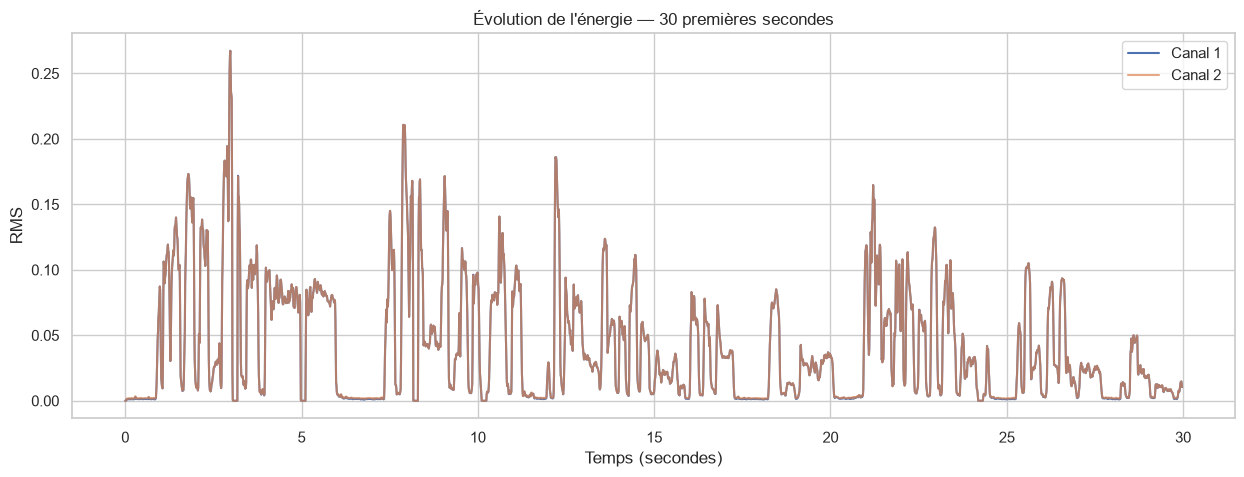

In [44]:
window_size = int(0.020 * sample_rate)  # 20 ms
hop_size = int(0.010 * sample_rate)     # 10 ms

# Limiter l'analyse aux 30 premières secondes
audio_30s = signal[:30 * sample_rate]

rms_channels = []

for channel in range(2):
    channel_signal = audio_30s[:, channel]

    rms = [
        np.sqrt(np.mean(
            channel_signal[i:i + window_size] ** 2
        ))
        for i in range(
            0,
            len(channel_signal) - window_size,
            hop_size
        )
    ]

    rms_channels.append(rms)

rms_channels = np.array(rms_channels)

rms_time = (
    np.arange(rms_channels.shape[1]) * hop_size
    / sample_rate
)

plt.figure(figsize=(15, 5))

plt.plot(rms_time, rms_channels[0], label="Canal 1")
plt.plot(rms_time, rms_channels[1], label="Canal 2", alpha=0.7)

plt.xlabel("Temps (secondes)")
plt.ylabel("RMS")
plt.title("Évolution de l'énergie — 30 premières secondes")
plt.legend()
plt.grid(True)
plt.show()

In [45]:
mono_signal = signal.mean(axis=1)

In [46]:
channel_correlations = []

for _, row in df.iterrows():
    audio, sr = sf.read(row["chemin_audio"])

    correlation = np.corrcoef(
        audio[:, 0],
        audio[:, 1]
    )[0, 1]

    channel_correlations.append({
        "titre": row["titre"],
        "correlation": correlation
    })

correlation_df = pd.DataFrame(channel_correlations)

display(
    correlation_df.describe().round(4)
)

,correlation
count,44.0000
mean,0.8426
std,0.1299
min,0.5713
25%,0.7109
50%,0.8762
75%,0.9231
max,1.0000


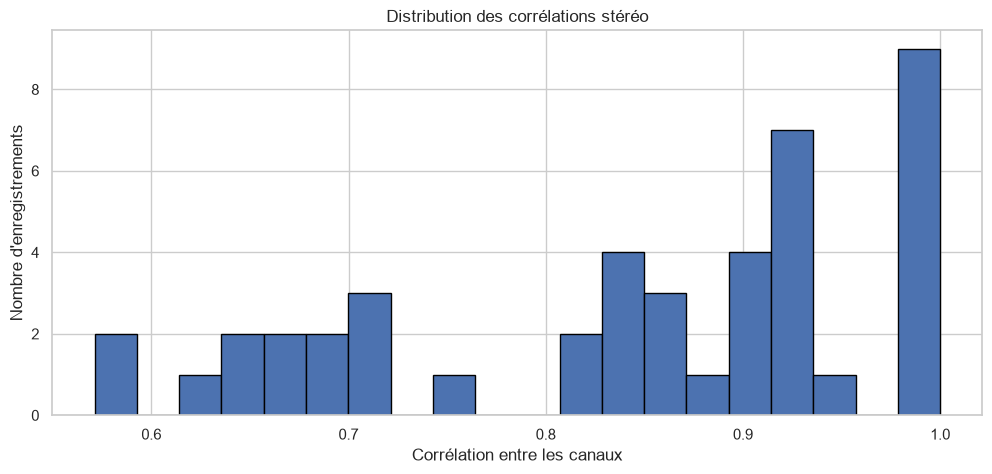

In [47]:
plt.figure(figsize=(12, 5))

plt.hist(
    correlation_df["correlation"],
    bins=20,
    edgecolor="black"
)

plt.xlabel("Corrélation entre les canaux")
plt.ylabel("Nombre d'enregistrements")
plt.title("Distribution des corrélations stéréo")

plt.show()

In [48]:
# Trier les enregistrements par corrélation croissante
correlation_sorted = correlation_df.sort_values(
    "correlation",
    ascending=True
)

display(correlation_sorted.head(10))

,titre,correlation
9,Jéjé Yi Koo ! (Hwèdè),0.571267
14,Agbotchébou Oun Wa Gbo Wé,0.582651
11,Noudé Wé W'ado B'adôwéhè Gbèdè Kô,0.627714
36,Djegou Djegou,0.638622
10,Fitè Mi Non Bo Dô E ?,0.650834
12,Gbonon Wunmè W'agbadé Non Mia Go Do,0.659167
37,Oun Koun Na Lon O,0.669300
7,Vodounsi Gansé Gansé Kou (Hwèdè),0.681999
34,Wounfianmon,0.689631
33,Kakpo Sin Han,0.703941


In [49]:
print("Statistiques des corrélations :")
display(correlation_df["correlation"].describe().round(4))

print(
    "Nombre d'enregistrements avec une corrélation < 0.8 :",
    (correlation_df["correlation"] < 0.8).sum()
)

Statistiques des corrélations :


count    44.0000
mean      0.8426
std       0.1299
min       0.5713
25%       0.7109
50%       0.8762
75%       0.9231
max       1.0000
Name: correlation, dtype: float64

Nombre d'enregistrements avec une corrélation < 0.8 : 13


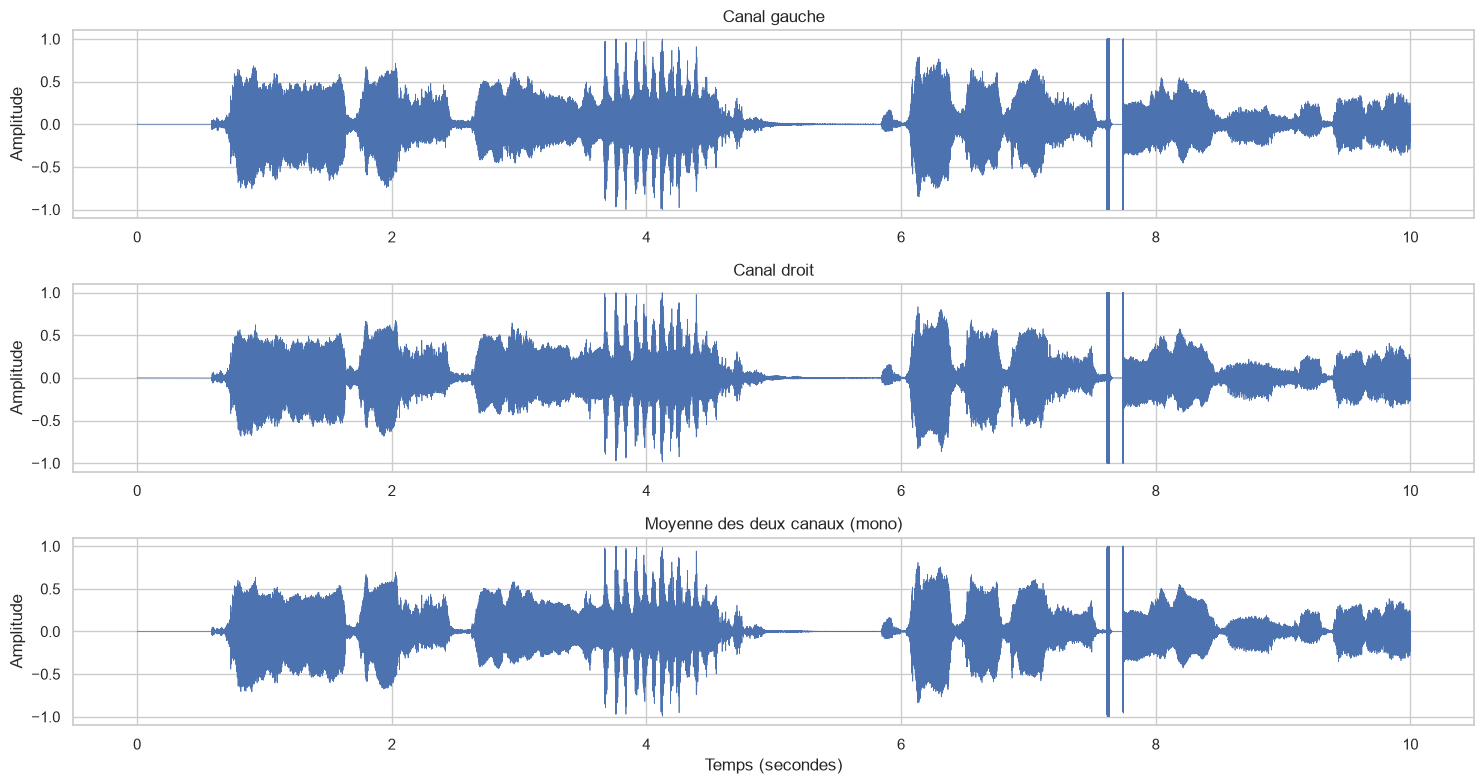

In [50]:
# Identifier le moins corrélé
worst_recording = correlation_sorted.iloc[0]

row = df.loc[
    df["titre"] == worst_recording["titre"]
].iloc[0]

audio, sr = sf.read(row["chemin_audio"])

mono = audio.mean(axis=1)

duration = 10
n = duration * sr
t = np.arange(n) / sr

plt.figure(figsize=(15, 8))

plt.subplot(3, 1, 1)
plt.plot(t, audio[:n, 0], linewidth=0.5)
plt.title("Canal gauche")
plt.ylabel("Amplitude")

plt.subplot(3, 1, 2)
plt.plot(t, audio[:n, 1], linewidth=0.5)
plt.title("Canal droit")
plt.ylabel("Amplitude")

plt.subplot(3, 1, 3)
plt.plot(t, mono[:n], linewidth=0.5)
plt.title("Moyenne des deux canaux (mono)")
plt.xlabel("Temps (secondes)")
plt.ylabel("Amplitude")

plt.tight_layout()
plt.show()

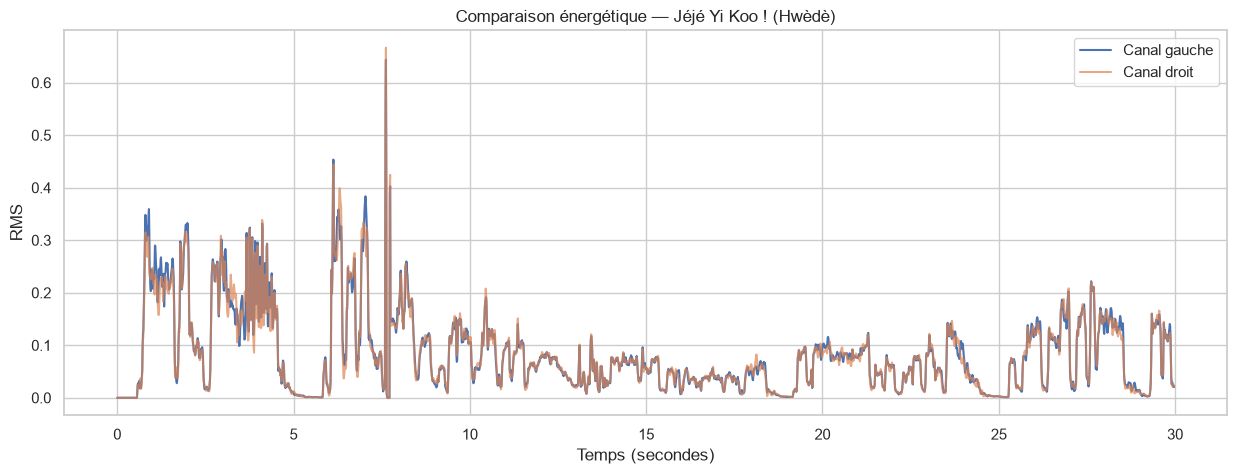

In [51]:
# Sélection du fichier le moins corrélé
idx = correlation_df["correlation"].idxmin()

row = df.loc[idx]

audio, sr = sf.read(row["chemin_audio"])

# Analyse des 30 premières secondes
audio = audio[:30 * sr]

window_size = int(0.020 * sr)
hop_size = int(0.010 * sr)

def calculate_rms(x, window_size, hop_size):
    return np.array([
        np.sqrt(np.mean(x[i:i + window_size] ** 2))
        for i in range(0, len(x) - window_size, hop_size)
    ])

rms_left = calculate_rms(audio[:, 0], window_size, hop_size)
rms_right = calculate_rms(audio[:, 1], window_size, hop_size)

time = np.arange(len(rms_left)) * hop_size / sr

plt.figure(figsize=(15, 5))

plt.plot(time, rms_left, label="Canal gauche")
plt.plot(time, rms_right, label="Canal droit", alpha=0.7)

plt.xlabel("Temps (secondes)")
plt.ylabel("RMS")
plt.title(f"Comparaison énergétique — {row['titre']}")
plt.legend()
plt.grid(True)
plt.show()